# Chapter 4: Deep RL — Case Study

## DQN vs REINFORCE vs Actor-Critic on CartPole

This notebook compares three deep reinforcement learning algorithms from Chapter 4 on the
CartPole-v1 environment using the package-based `rlbook` helpers. It follows the cleaned-up
workflow of the original notebook while preserving the updated Chapter 4 content:
multi-seed training, fixed-step evaluation, and an optional Double DQN ablation.


In [1]:
# Setup — run once
# Repo / local package layout:
#   rlbook/
#     environments/
#     core/
#     algorithms/deep/
#
# If you are running this notebook outside the project root, make sure the
# project root is on PYTHONPATH or install the package in editable mode.

import json
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# Small MLPs on CartPole are typically faster on CPU with a single thread.
torch.set_num_threads(1)
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

from rlbook.environments import CartPoleWrapper
from rlbook.algorithms.deep import (
    RunConfig,
    DQNConfig,
    run_reinforce,
    run_actor_critic,
    run_dqn,
)


Device: cuda


## 1. Environment

In [3]:
env = CartPoleWrapper(seed=42)
print(f"Observation dim: {env.state_dim}, Actions: {env.n_actions}")
print("CartPole-v1 is typically considered solved near mean return ≥ 475 over 100 episodes.")

Observation dim: 4, Actions: 2
CartPole-v1 is typically considered solved near mean return ≥ 475 over 100 episodes.


## 2. Training All Algorithms

The default preset matches the updated Chapter 4 notebook:
- 3 training seeds
- 20k environment-step budget per seed
- evaluation every 1k steps
- optional Double DQN ablation

For a quick smoke test, reduce `SEEDS`, `eval_episodes`, or `total_step_budget`.


In [4]:
LOGDIR = Path("logs")
LOGDIR.mkdir(exist_ok=True)

SEEDS = [101, 202, 303]
INCLUDE_DOUBLE_DQN = False  # set True to include the optional Double DQN ablation

run_cfg = RunConfig(
    gamma=0.99,
    episodes=10_000,
    steps_per_episode=500,   # CartPole-v1 caps episodes at 500 steps
    eval_every_steps=1_000,  # denser checkpoints; keep 10_000 if you only want 10k/20k points
    eval_episodes=5,
    total_step_budget=20_000,
)

all_logs = []

for seed in SEEDS:
    print(f"\n--- Seed {seed} ---")

    # REINFORCE
    print("[1/3] REINFORCE")
    all_logs.extend(
        run_reinforce(seed, CartPoleWrapper(seed=seed), run_cfg, lr=1e-3)
    )

    # Actor-Critic
    print("[2/3] Actor-Critic")
    all_logs.extend(
        run_actor_critic(
            seed,
            CartPoleWrapper(seed=seed),
            run_cfg,
            actor_lr=3e-4,
            critic_lr=1e-3,
        )
    )

    # DQN
    print("[3/3] DQN")
    all_logs.extend(
        run_dqn(
            seed,
            CartPoleWrapper(seed=seed),
            run_cfg,
            DQNConfig(double_dqn=False),
        )
    )

    # Optional Double DQN ablation
    if INCLUDE_DOUBLE_DQN:
        all_logs.extend(
            run_dqn(
                seed,
                CartPoleWrapper(seed=seed),
                run_cfg,
                DQNConfig(double_dqn=True),
            )
        )

log_path = LOGDIR / "cartpole_logs_ch4.jsonl"
with log_path.open("w") as f:
    for row in all_logs:
        f.write(json.dumps(row) + "\n")

print(f"Saved {len(all_logs)} log rows to {log_path}")


--- Seed 101 ---
[1/3] REINFORCE
[2/3] Actor-Critic
[3/3] DQN

--- Seed 202 ---
[1/3] REINFORCE
[2/3] Actor-Critic
[3/3] DQN

--- Seed 303 ---
[1/3] REINFORCE
[2/3] Actor-Critic
[3/3] DQN
Saved 180 log rows to logs\cartpole_logs_ch4.jsonl


## 3. Learning Curves

### Individual Algorithm Curves


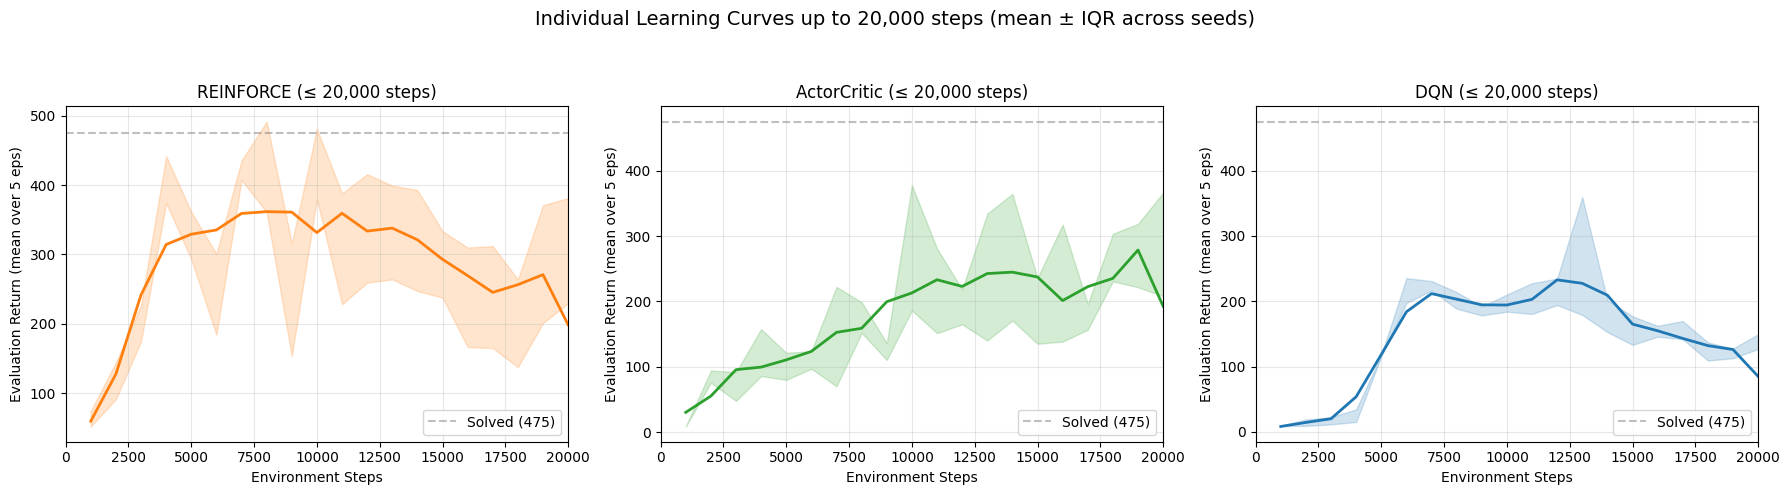

In [5]:
rows = []
with log_path.open() as f:
    for line in f:
        rows.append(json.loads(line))

by_algo = defaultdict(lambda: defaultdict(list))
for r in rows:
    by_algo[r["algo"]][r["steps"]].append(r["return_mean"])

colors = {
    "REINFORCE": "tab:orange",
    "ActorCritic": "tab:green",
    "DQN": "tab:blue",
    "DoubleDQN": "tab:purple",
}

STEP_CAP = 20_000
EVAL_EPISODES = 5  # matches run_cfg.eval_episodes

def moving_avg(y, k=3):
    y = np.asarray(y, dtype=np.float32)
    if len(y) < k or k <= 1:
        return y
    kernel = np.ones(k, dtype=np.float32) / k
    return np.convolve(y, kernel, mode="same")

algos = [algo for algo in colors if algo in by_algo]
fig, axes = plt.subplots(1, len(algos), figsize=(6 * len(algos), 5), squeeze=False)

for ax, algo in zip(axes.flat, algos):
    data = by_algo[algo]
    xs = np.array(sorted(data.keys()), dtype=np.int64)
    vals = [data[s] for s in xs]
    ys = np.array([np.mean(v) for v in vals], dtype=np.float32)
    q25 = np.array([np.percentile(v, 25) for v in vals], dtype=np.float32)
    q75 = np.array([np.percentile(v, 75) for v in vals], dtype=np.float32)

    mask = xs <= STEP_CAP
    xs, ys, q25, q75 = xs[mask], ys[mask], q25[mask], q75[mask]
    if len(xs) == 0:
        ax.set_visible(False)
        continue

    ax.plot(xs, moving_avg(ys, k=3), color=colors[algo], lw=2)
    ax.fill_between(xs, q25, q75, alpha=0.2, color=colors[algo])
    ax.axhline(475, color="gray", ls="--", alpha=0.5, label="Solved (475)")
    ax.set_xlim(0, STEP_CAP)
    ax.set_xlabel("Environment Steps")
    ax.set_ylabel(f"Evaluation Return (mean over {EVAL_EPISODES} eps)")
    ax.set_title(f"{algo} (≤ {STEP_CAP:,} steps)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="lower right")

plt.suptitle(
    f"Individual Learning Curves up to {STEP_CAP:,} steps (mean ± IQR across seeds)",
    fontsize=14,
)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

### Combined Comparison

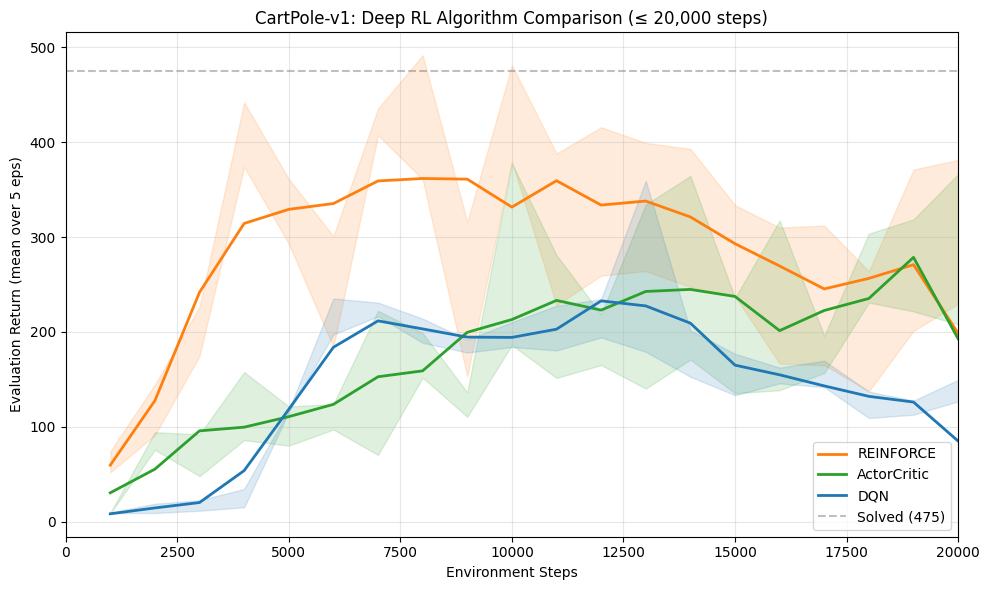

In [6]:
STEP_CAP = 20_000
EVAL_EPISODES = 5  # matches run_cfg.eval_episodes

plt.figure(figsize=(10, 6))

for algo in algos:
    data = by_algo[algo]
    xs = np.array(sorted(data.keys()), dtype=np.int64)
    vals = [data[s] for s in xs]
    ys = np.array([np.mean(v) for v in vals], dtype=np.float32)
    q25 = np.array([np.percentile(v, 25) for v in vals], dtype=np.float32)
    q75 = np.array([np.percentile(v, 75) for v in vals], dtype=np.float32)

    mask = xs <= STEP_CAP
    xs, ys, q25, q75 = xs[mask], ys[mask], q25[mask], q75[mask]
    if len(xs) == 0:
        continue

    plt.plot(xs, moving_avg(ys, k=3), color=colors[algo], lw=2, label=algo)
    plt.fill_between(xs, q25, q75, alpha=0.15, color=colors[algo])

plt.axhline(475, color="gray", ls="--", alpha=0.5, label="Solved (475)")
plt.xlim(0, STEP_CAP)
plt.xlabel("Environment Steps")
plt.ylabel(f"Evaluation Return (mean over {EVAL_EPISODES} eps)")
plt.title(f"CartPole-v1: Deep RL Algorithm Comparison (≤ {STEP_CAP:,} steps)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Summary Statistics

In [7]:
def solved(returns, threshold=475):
    return any(r >= threshold for r in returns)

def auc(data):
    xs = np.array(sorted(data.keys()), dtype=np.float32)
    ys = np.array([np.mean(data[s]) for s in xs], dtype=np.float32)
    return float(np.trapezoid(ys, xs))

summary_rows = []
for algo in algos:
    data = by_algo[algo]
    xs = sorted(data.keys())
    final_returns = np.array(data[xs[-1]], dtype=np.float32)
    all_returns = [v for s in xs for v in data[s]]

    summary_rows.append({
        "Algorithm": algo,
        "Final Return Mean": float(np.mean(final_returns)),
        "Final Return Std": float(np.std(final_returns)),
        "AUC": auc(data),
        "Solved?": "Yes" if solved(all_returns) else "No",
    })

summary_df = pd.DataFrame(summary_rows)
summary_df

,Algorithm,Final Return Mean,Final Return Std,AUC,Solved?
0,REINFORCE,304.333344,123.824860,5646599.5,Yes
1,ActorCritic,302.399994,136.226089,3500200.0,Yes
2,DQN,134.666672,20.985287,2857600.0,Yes


### Final Performance Bar Chart

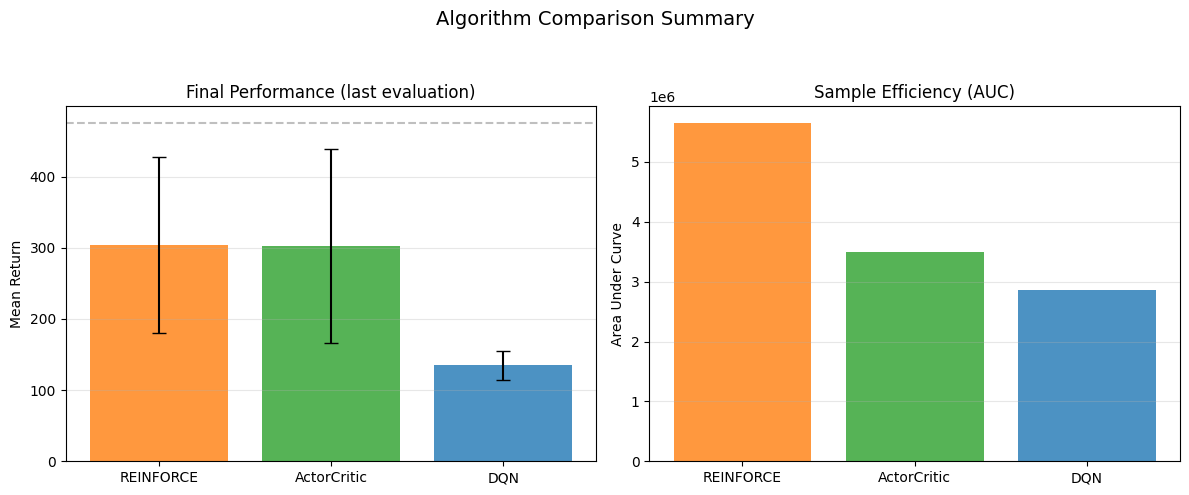

In [8]:
final_means = []
final_stds = []
aucs = []

for algo in algos:
    data = by_algo[algo]
    xs = sorted(data.keys())
    final = np.array(data[xs[-1]], dtype=np.float32)
    final_means.append(float(np.mean(final)))
    final_stds.append(float(np.std(final)))
    aucs.append(auc(data))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.bar(algos, final_means, yerr=final_stds, capsize=5,
        color=[colors[a] for a in algos], alpha=0.8)
ax1.axhline(475, color="gray", ls="--", alpha=0.5)
ax1.set_ylabel("Mean Return")
ax1.set_title("Final Performance (last evaluation)")
ax1.grid(axis="y", alpha=0.3)

ax2.bar(algos, aucs, color=[colors[a] for a in algos], alpha=0.8)
ax2.set_ylabel("Area Under Curve")
ax2.set_title("Sample Efficiency (AUC)")
ax2.grid(axis="y", alpha=0.3)

plt.suptitle("Algorithm Comparison Summary", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

## Key Takeaways

DQN benefits from experience replay and a target network, which typically improves
sample efficiency and training stability on CartPole. REINFORCE is the simplest policy
gradient baseline but has noticeably higher variance because it relies on full-episode
Monte Carlo returns. Actor-Critic reduces variance with a learned value baseline and
usually becomes competitive after enough interaction steps. If `INCLUDE_DOUBLE_DQN`
is enabled, the notebook also reports the optional Double DQN ablation using the same
helper-file architecture.
